# Laboratorio 2 · Descriptivas, forma y atípicos

Descriptivas calculadas con todas las filas. step y monto usan transacciones; conteo y monto promedio usan horas. No se mezclan las unidades.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from engine import fmt, pformat, load_dataset, run_full_analysis, descriptive_stats
from narrative import sections
r = json.loads((ROOT / 'results/analysis_summary.json').read_text(encoding='utf-8'))
h = pd.read_csv(ROOT / 'results/hourly_series.csv')
pd.options.display.float_format = lambda x: f'{x:.4f}'
def tabla(rows):
    frame = pd.DataFrame(rows)
    for col in frame:
        if col.endswith('_p') or col == 'p_value': frame[col] = frame[col].map(pformat)
    display(frame)
def apartado(i):
    title, texts = sections(r)[i-1]
    display(Markdown('## ' + title))
    for text in texts: display(Markdown(text))
def figura(name):
    display(Image(filename=str(ROOT / 'results/figures' / name), width=850))


In [2]:
apartado(2)

## 2. Tendencia central, dispersión y posición

Se analizan step y monto a nivel transacción, y transacciones_hora y monto_promedio a nivel hora. No se copia el conteo de una hora a cada transacción para volver a calcular sus descriptivas: eso ponderaría excesivamente las horas activas. La varianza usa n-1; cuantiles con interpolación lineal; CV = 100 s / |media|. La moda se calcula por valor exacto, se informa multiplicidad si existe empate.

Monto: media 179861.9035, mediana 74871.9400, moda 10000000.0000. La media superior a la mediana indica influencia de la cola derecha. La moda de un monto redondeado puede reflejar reglas o importes repetidos del simulador; no implica que sea un monto típico de la mayoría.

El 50% central de montos se sitúa entre Q1=13389.5700 y Q3=208721.4775. P10=4501.3000 y P90=365423.3090 delimitan el 80% central. El rango es 92445516.6400; la desviación estándar es 603858.2315.

La tabla adjunta contiene las medidas completas. Entre variables de razón comparables, la mayor dispersión relativa es monto. El CV de step se muestra para completar el cálculo, pero su origen temporal es arbitrario y cambia si se traslada el índice, por lo que no es una comparación sustantiva de variabilidad.

En el objetivo horario, media=8563.4186, mediana=529.0000. La diferencia refleja heterogeneidad entre horas activas y horas con actividad baja. No demuestra por sí sola una tendencia temporal.

In [3]:
ds = pd.DataFrame(r['descriptive_statistics']).set_index('variable')
fields = ['n','media','mediana','moda','rango','varianza_muestral','desviacion_estandar',
          'coeficiente_variacion_porcentaje','p10','q1','q2','q3','p90']
display(ds[fields].T)
# Verificación independiente sobre la serie horaria completa.
check = descriptive_stats(h.transacciones_hora, 'transacciones_hora', 'hora')
assert np.isclose(check['media'], ds.loc['transacciones_hora', 'media'])
assert np.isclose(h.transacciones_hora.var(ddof=1), ds.loc['transacciones_hora','varianza_muestral'])

variable,step,monto,transacciones_hora,monto_promedio
n,6362620.0000,6362620.0000,743.0000,743.0000
media,243.3972,179861.9035,8563.4186,701708.6334
mediana,239.0000,74871.9400,529.0000,210260.1152
moda,19.0000,10000000.0000,10.0000,NaN
rango,742.0000,92445516.6400,51350.0000,6185561.5020
varianza_muestral,20258.3900,364644763705.5444,179257106.0631,922458462427.4159
desviacion_estandar,142.3320,603858.2315,13388.6932,960447.0118
coeficiente_variacion_porcentaje,58.4772,335.7344,156.3475,136.8726
p10,35.0000,4501.3000,8.0000,117264.1294
q1,156.0000,13389.5700,12.0000,148538.6197


In [4]:
apartado(3)

## 3. Forma, gráficos y valores atípicos

Monto tiene asimetría Fisher=30.9939, curtosis Pearson=1800.9567 y exceso=1797.9567. Se clasifica como asimétrica positiva y leptocúrtica. El exceso se obtiene restando 3 a la curtosis Pearson. Una curtosis elevada describe colas y extremos; no equivale simplemente a mayor altura del pico.

Se usa la convención descriptiva |asimetría| <= 0.5 para simetría aproximada y |exceso| <= 0.1 para mesocurtosis aproximada; son umbrales de lectura, no pruebas de normalidad. Histogramas y boxplots se construyen para las variables cuantitativas, y barras para las categorías. Las figuras transaccionales usan hasta 100000 filas (semilla 42); las tablas usan el total.

Con IQR=Q3-Q1=195331.9075, los límites de Tukey son -279608.2913 y 501719.3387. Hay 338,078 montos fuera de ellos (5.3135%). Como sensibilidad, al excluirlos la media pasa de 179861.9035 a 111534.1803 y la desviación de 603858.2315 a 120398.3069. La mediana sin extremos es 63175.8150.

Los atípicos no son automáticamente errores ni fraude. Las horas de mayor actividad pueden ser parte de la estacionalidad. Para modelar monto se propone comparar log1p(monto) y métodos robustos conservando el original. No se garantiza normalidad ni homocedasticidad con una transformación.

In [5]:
display(ds[['asimetria_fisher','curtosis_pearson','exceso_curtosis','clasificacion_asimetria','clasificacion_curtosis']])
display(ds[['iqr','limite_inferior_iqr','limite_superior_iqr','n_outliers_iqr','porcentaje_outliers_iqr','media_sin_atipicos','mediana_sin_atipicos','desviacion_sin_atipicos']])

,asimetria_fisher,curtosis_pearson,exceso_curtosis,clasificacion_asimetria,clasificacion_curtosis
variable,,,,,
step,0.3752,3.3291,0.3291,aproximadamente simétrica,leptocúrtica
monto,30.9939,1800.9567,1797.9567,asimétrica positiva,leptocúrtica
transacciones_hora,1.3891,3.4629,0.4629,asimétrica positiva,leptocúrtica
monto_promedio,2.4435,9.8431,6.8431,asimétrica positiva,leptocúrtica


,iqr,limite_inferior_iqr,limite_superior_iqr,n_outliers_iqr,porcentaje_outliers_iqr,media_sin_atipicos,mediana_sin_atipicos,desviacion_sin_atipicos
variable,,,,,,,,
step,179.0000,-112.5000,603.5000,102688,1.6139,236.3396,236.0000,132.2522
monto,195331.9075,-279608.2913,501719.3387,338078,5.3135,111534.1803,63175.8150,120398.3069
transacciones_hora,12305.0000,-18445.5000,30774.5000,87,11.7093,4773.8506,53.5000,8762.4834
monto_promedio,730653.8620,-947442.1733,1975173.2746,75,10.0942,436984.1945,190196.0981,465736.6241


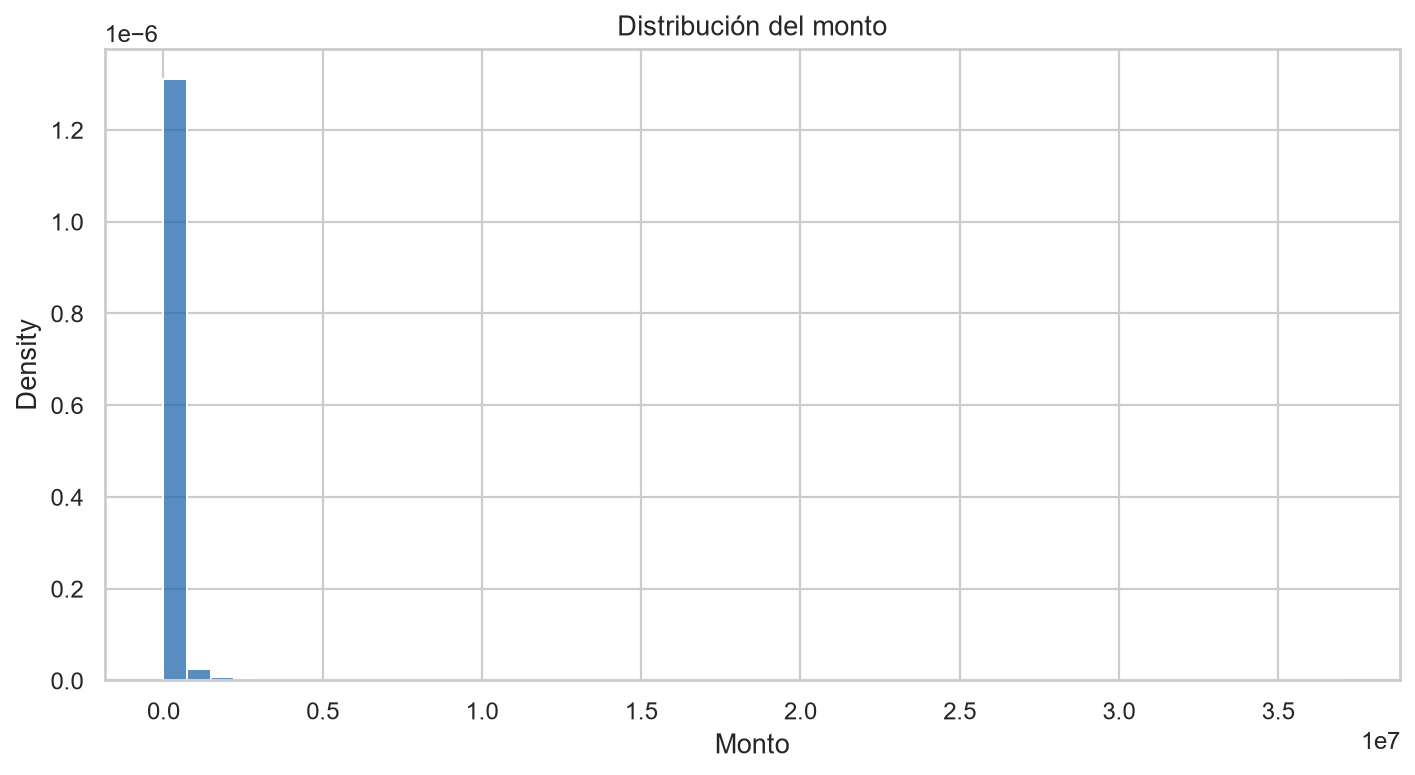

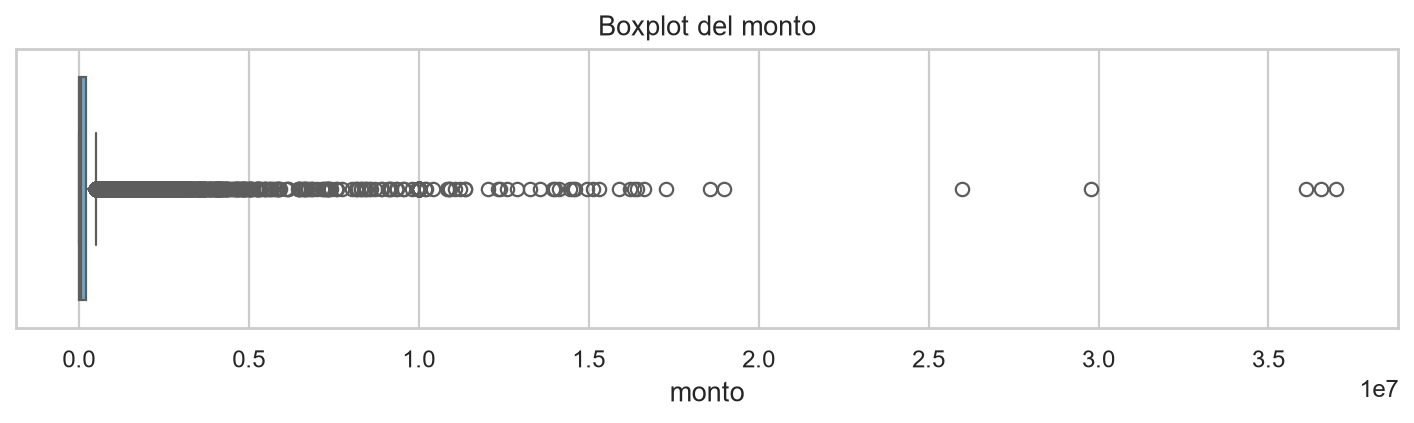

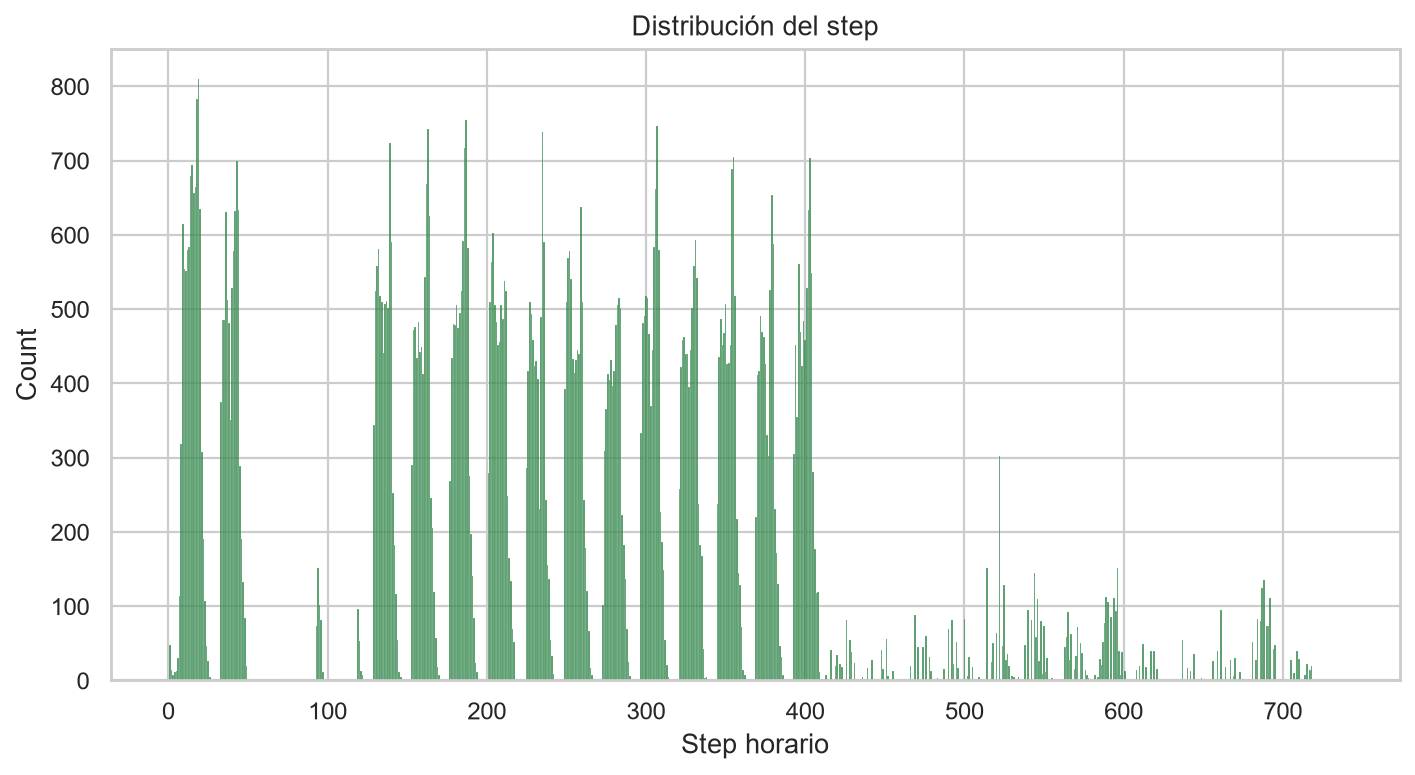

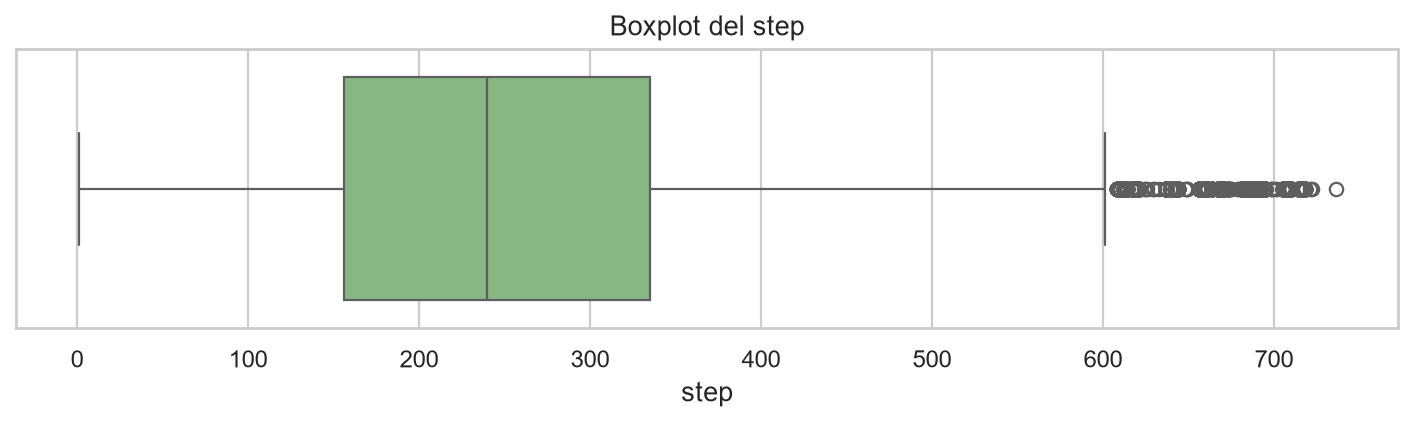

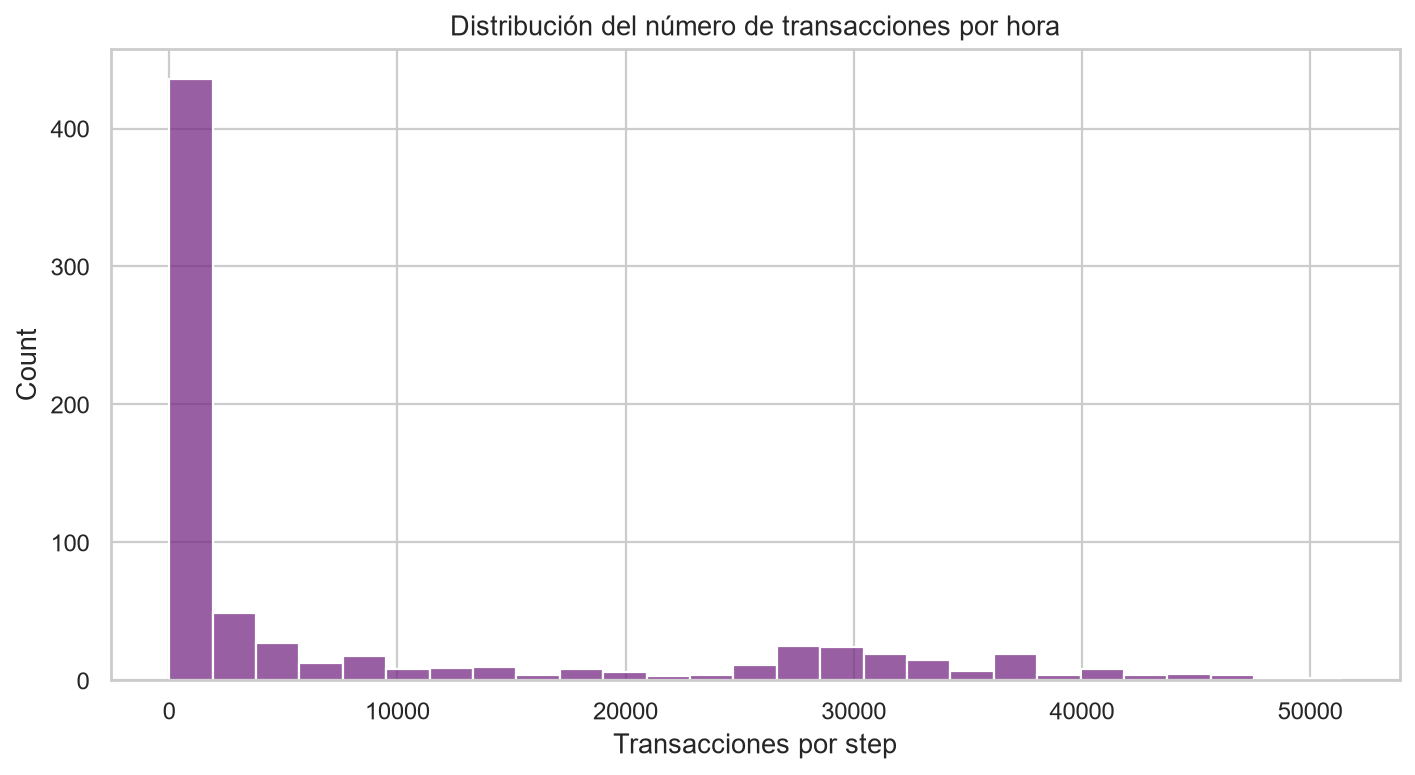

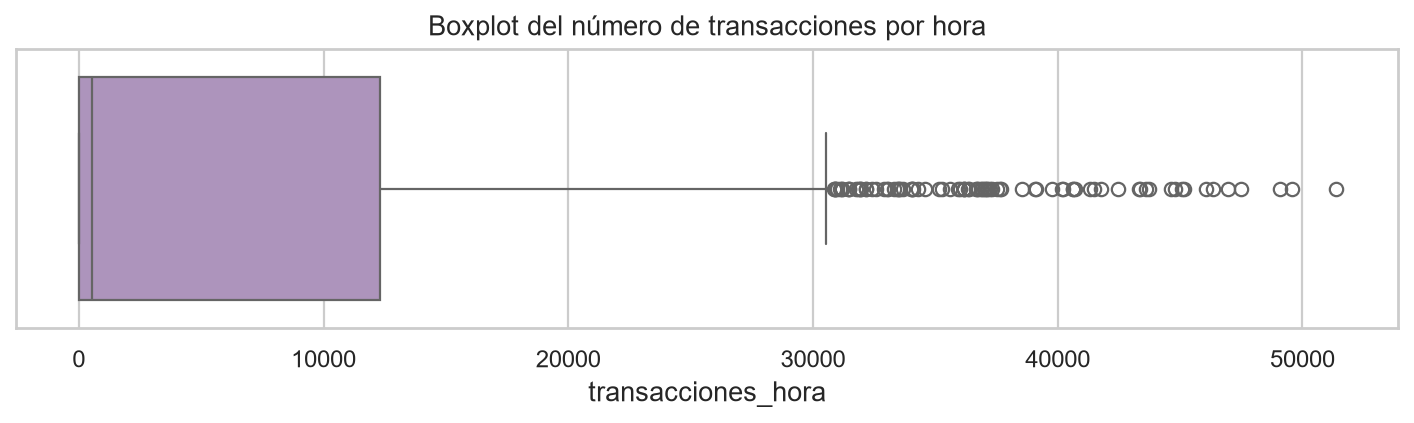

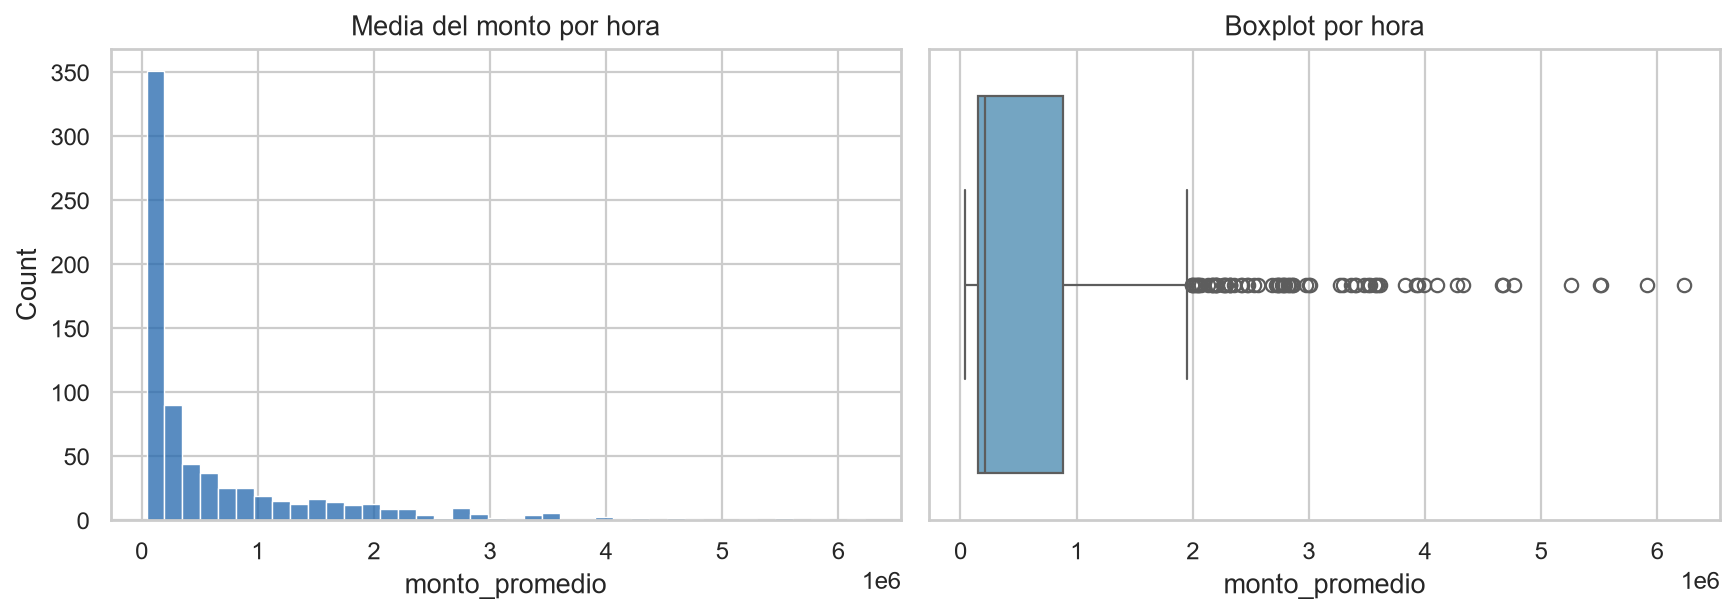

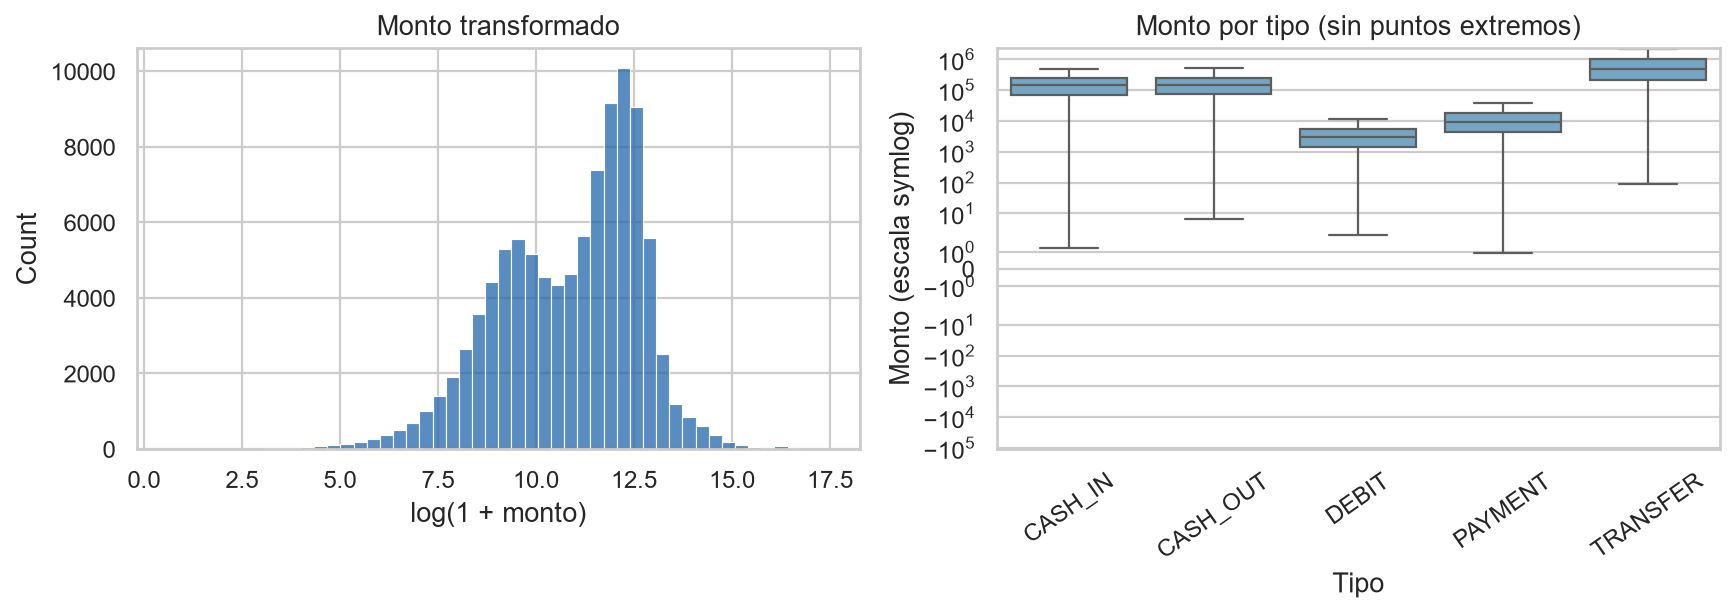

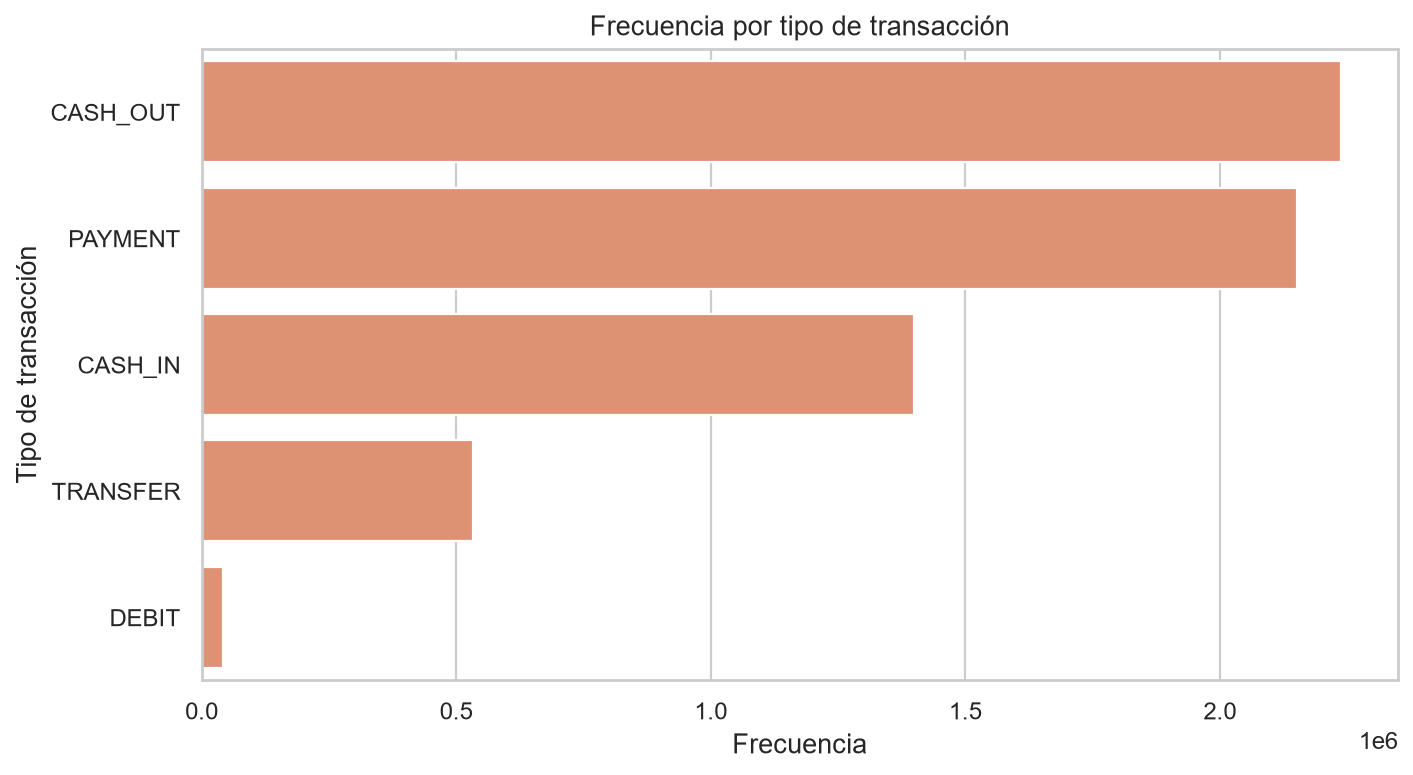

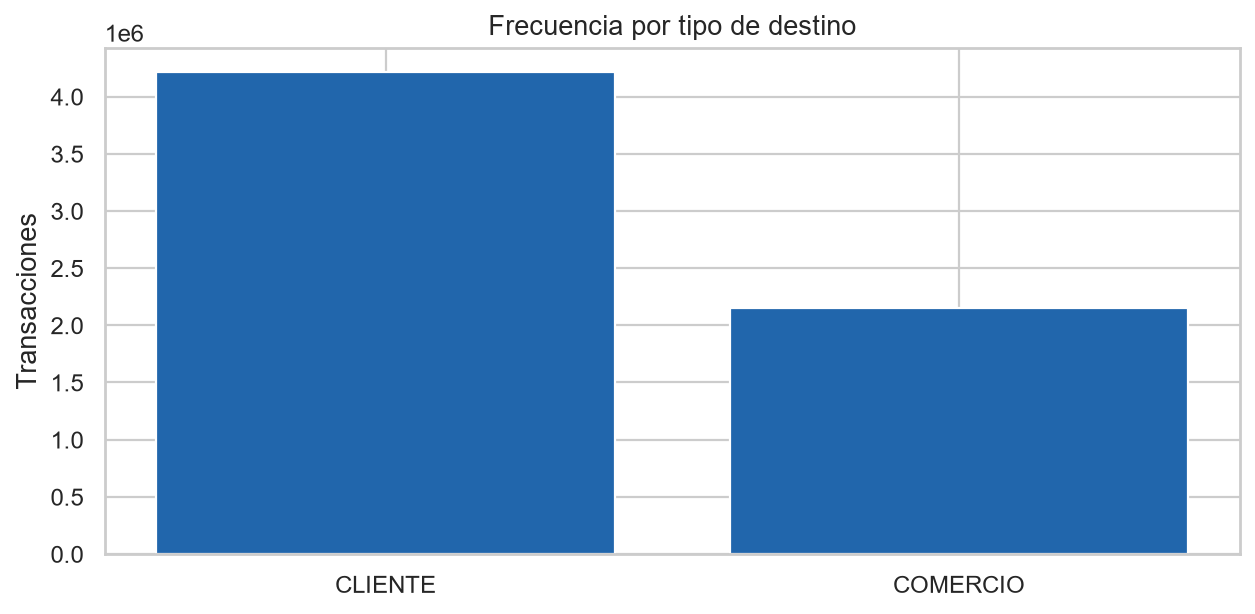

In [6]:
for name in ['histograma_monto.png','boxplot_monto.png','histograma_step.png','boxplot_step.png','histograma_transacciones_hora.png','boxplot_transacciones_hora.png','distribucion_monto_promedio.png','monto_transformado_grupos.png','barras_tipo_transaccion.png','barras_tipo_destino.png']:
    figura(name)

Las gráficas de transacciones usan hasta 100000 observaciones con semilla 42. El resultado numérico usa el total. En monto se incluyen escalas original y log1p para ver la cola y el cuerpo. La exclusión IQR se presenta como sensibilidad, no como borrado de datos.